<a href="https://colab.research.google.com/github/muralisagili007-del/EDA-PROJECT/blob/main/Logistics_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("/content/Social_Network_Ads.csv")

In [ ]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB


In [ ]:
df.tail()

,User ID,Gender,Age,EstimatedSalary,Purchased
395,15691863,Female,46,41000,1
396,15706071,Male,51,23000,1
397,15654296,Female,50,20000,1
398,15755018,Male,36,33000,0
399,15594041,Female,49,36000,1


In [ ]:
df = df.drop(columns=["Gender"], errors="ignore")
df.head()

,User ID,EstimatedSalary,Purchased
0,15624510,19000,0
1,15810944,20000,0
2,15668575,43000,0
3,15603246,57000,0
4,15804002,76000,0


In [ ]:
df.isnull().sum()

,0
User ID,0
Gender,0
EstimatedSalary,0
Purchased,0


In [ ]:
# Since Gender was dropped in a later step, we only need to impute 'Purchased' if needed
df['Purchased'] = df['Purchased'].fillna(df['Purchased'].median())

In [ ]:
df.isnull().sum()

,0
User ID,0
EstimatedSalary,0
Purchased,0


<Axes: xlabel='EstimatedSalary'>

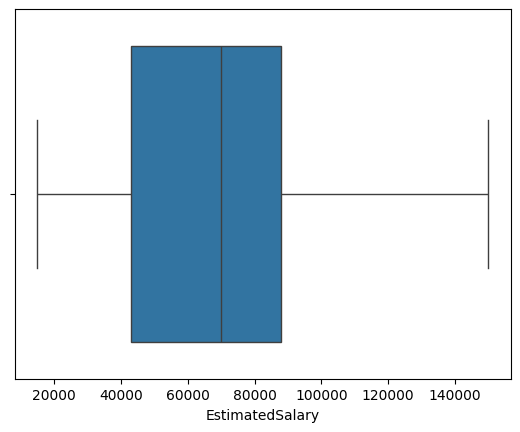

In [ ]:
sns.boxplot(x=df['EstimatedSalary'])

<Axes: ylabel='EstimatedSalary'>

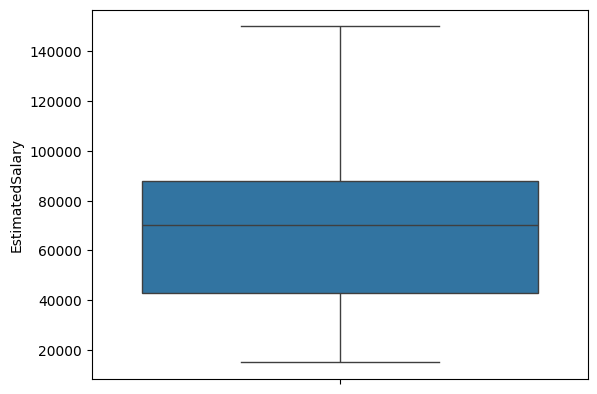

In [ ]:
sns.boxplot(y=df['EstimatedSalary'])

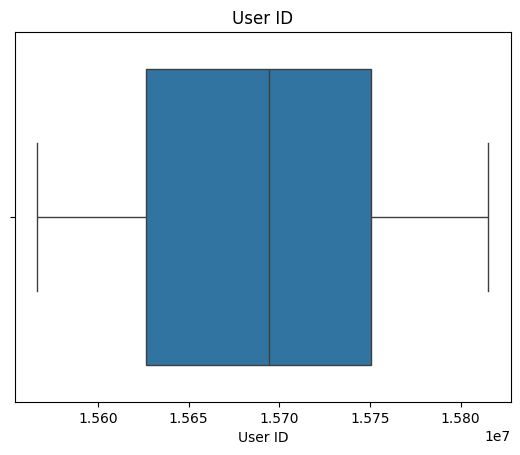

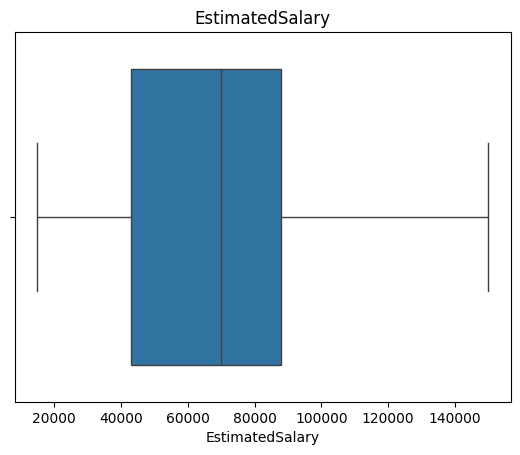

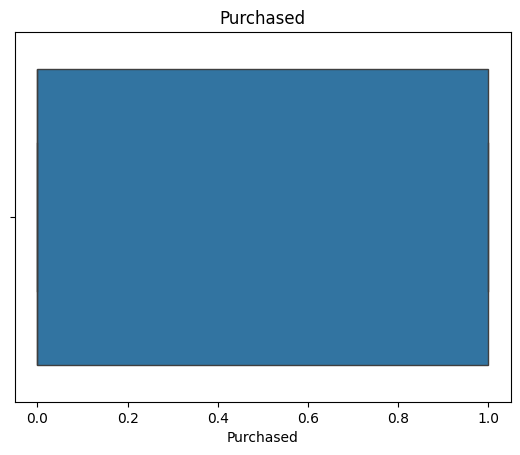

In [ ]:
for col in df.select_dtypes(include = 'number').columns:
  sns.boxplot(x= df[col])
  plt.title(col)
  plt.show()

In [ ]:
X = df.drop("Purchased", axis = 1)
y = df["Purchased"]

In [ ]:
print(X.shape)
print(y.shape)

(400, 2)
(400,)


In [ ]:
df=pd.get_dummies(df,columns=['Purchased','EstimatedSalary'],drop_first=True,dtype=int)
df.head()

,User ID,Purchased_1,EstimatedSalary_16000,EstimatedSalary_17000,EstimatedSalary_18000,EstimatedSalary_19000,EstimatedSalary_20000,EstimatedSalary_21000,EstimatedSalary_22000,EstimatedSalary_23000,...,EstimatedSalary_139000,EstimatedSalary_141000,EstimatedSalary_142000,EstimatedSalary_143000,EstimatedSalary_144000,EstimatedSalary_146000,EstimatedSalary_147000,EstimatedSalary_148000,EstimatedSalary_149000,EstimatedSalary_150000
0,15624510,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,15810944,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,15668575,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,15603246,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,15804002,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
from sklearn.model_selection import train_test_split

# Recreate X and y using the processed dataframe 'df' with the correct column name
X = df.drop('Purchased_1', axis=1)
y = df['Purchased_1']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Start clean with the original dataset
clean_df = pd.read_csv('/content/Social_Network_Ads.csv')

# 2. Drop 'User ID' as it is a unique identifier and not a predictive feature
clean_df = clean_df.drop(columns=['User ID'], errors='ignore')

# 3. Encode categorical columns correctly (Gender is binary, so drop_first=True makes it 1 column)
clean_df = pd.get_dummies(clean_df, columns=['Gender'], drop_first=True, dtype=int)

# 4. Split features and target (Purchased is our target)
X = clean_df.drop('Purchased', axis=1)
y = clean_df['Purchased']

# 5. Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# 6. Scale numerical features (Age and EstimatedSalary) for better Logistic Regression performance
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

numerical_cols = ['Age', 'EstimatedSalary']
X_train_scaled[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test_scaled[numerical_cols] = scaler.transform(X_test[numerical_cols])

# 7. Train the model on scaled data
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

print("Features used for training:", list(X_train.columns))
print("Training Accuracy:", model.score(X_train_scaled, y_train))
print("Testing Accuracy:", model.score(X_test_scaled, y_test))

Features used for training: ['Age', 'EstimatedSalary', 'Gender_Male']
Training Accuracy: 0.853125
Testing Accuracy: 0.8125


In [ ]:
from sklearn.linear_model import LogisticRegression

# Instantiate and train the model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)
print(y_pred)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0]


In [ ]:
from sklearn.metrics import accuracy_score
print("Accuracy:",accuracy_score(y_test,y_pred))

Accuracy: 0.6375


In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.64      1.00      0.78        51
           1       0.00      0.00      0.00        29

    accuracy                           0.64        80
   macro avg       0.32      0.50      0.39        80
weighted avg       0.41      0.64      0.50        80



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
y_pred=model.predict(X_test)
print(y_pred)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0]


In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[51  0]
 [29  0]]


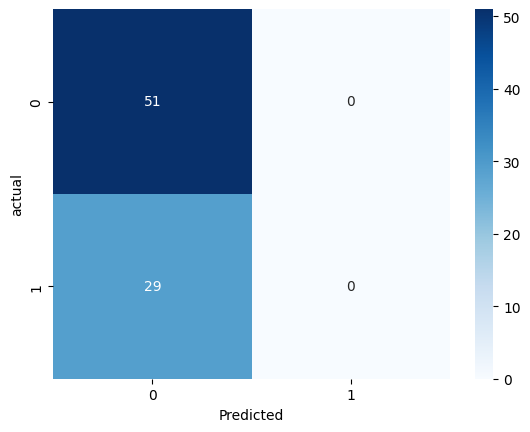

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.heatmap(cm, annot=True,fmt ='d',cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("actual")
plt.show()

In [ ]:
print(X.columns)
print("training Accuracy:", model.score(X_train, y_train))
print("testing Accuracy:", model.score(X_test, y_test))

Index(['User ID', 'EstimatedSalary_16000', 'EstimatedSalary_17000',
       'EstimatedSalary_18000', 'EstimatedSalary_19000',
       'EstimatedSalary_20000', 'EstimatedSalary_21000',
       'EstimatedSalary_22000', 'EstimatedSalary_23000',
       'EstimatedSalary_25000',
       ...
       'EstimatedSalary_139000', 'EstimatedSalary_141000',
       'EstimatedSalary_142000', 'EstimatedSalary_143000',
       'EstimatedSalary_144000', 'EstimatedSalary_146000',
       'EstimatedSalary_147000', 'EstimatedSalary_148000',
       'EstimatedSalary_149000', 'EstimatedSalary_150000'],
      dtype='object', length=117)
training Accuracy: 0.64375
testing Accuracy: 0.6375
